## 1. Установка

In [ ]:
#@title Проверка GPU и установка пакетов
import os, subprocess
if subprocess.run('nvidia-smi', shell=True).returncode:
    raise RuntimeError('Нет GPU. Среда выполнения -> Сменить среду выполнения -> GPU.')
!pip uninstall -y -q jax-cuda13-plugin jax-cuda13-pjrt jax-cuda12-plugin jax-cuda12-pjrt
!pip install -q "jax[cuda12]==0.6.2" "jaxlib==0.6.2" "flax==0.11.2" "brax==0.14.2" "orbax-checkpoint==0.11.31" "optax==0.2.6" "chex==0.1.90" "mujoco==3.6.0" "mujoco-mjx==3.6.0" "warp-lang==1.11.0" "playground==0.2.0" mediapy pandas
!pip list 2>/dev/null | grep -i -E '^(jax|jaxlib|jax-cuda[0-9]+-(plugin|pjrt)|flax|brax|mujoco|mujoco-mjx|warp-lang|orbax-checkpoint|playground) '
!command -v ffmpeg >/dev/null || (apt-get -qq update && apt-get -qq install -y ffmpeg)
NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
    os.makedirs(os.path.dirname(NVIDIA_ICD_CONFIG_PATH), exist_ok=True)
    with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
        f.write('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}')
os.environ['MUJOCO_GL'] = 'egl'
os.environ['XLA_FLAGS'] = os.environ.get('XLA_FLAGS', '') + ' --xla_gpu_triton_gemm_any=True'

brax                                  0.14.2
flax                                  0.11.2
jax                                   0.6.2
jax-cuda12-pjrt                       0.6.2
jax-cuda12-plugin                     0.6.2
jaxlib                                0.6.2
mujoco                                3.6.0
mujoco-mjx                            3.6.0
orbax-checkpoint                      0.11.31
playground                            0.2.0
warp-lang                             1.11.0


In [ ]:
#@title Импорты
import functools, json, time, pickle, importlib, shutil
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import mediapy as media

import jax
import jax.numpy as jp
import mujoco
from mujoco import mjx

from brax.training.agents.ppo import networks as ppo_networks
from brax.training.agents.ppo import train as ppo

from mujoco_playground import registry, wrapper
from mujoco_playground.config import locomotion_params
from mujoco_playground._src import mjx_env
from mujoco_playground._src.locomotion.go1 import joystick as go1_joystick

print('JAX devices:', jax.devices())
assert any(d.platform == 'gpu' for d in jax.devices()), 'JAX не видит GPU'
np.set_printoptions(precision=3, suppress=True, linewidth=120)

JAX devices: [CudaDevice(id=0)]


In [ ]:
#@title Параметры обучения
SEED = 0
NUM_TIMESTEPS = 500_000_000   #@param {type:"integer"}  # меньше - быстрее, но хуже походка
IMPL = 'warp'                 #@param ["warp", "jax"]  # если 'warp' падает с ошибкой, попробуйте 'jax'
SIM_DT = 0.002
CTRL_DT = 0.02

KP, KD = 100.0, 0.5
ACTION_SCALE = 0.5
MAX_DELTA = float(np.deg2rad(4.9))
DEFAULT_POSE = np.array([0.0, 0.9, -1.8] * 4)
INIT_HEIGHT = 0.27

# Пределы суставов из ТЗ T2 (с запасом 0.02 рад)
Q_MIN = np.array([-0.863, -0.686, -2.818] * 4)
Q_MAX = np.array([0.863, 4.501, -0.888] * 4)
Q_LO, Q_HI = Q_MIN + 0.02, Q_MAX - 0.02

JOINT_DAMPING_SIM = np.array([1.0, 2.0, 2.0] * 4)
ARMATURE_SIM = 0.01
FRICTIONLOSS_SIM = 0.2

# Команды скорости
VX_RANGE = (0.15, 0.7)
P_ZERO_CMD = 0.05
# Условия падения из ТЗ T3 (используем как условие окончания эпизода при обучении)
FALL_HEIGHT = 0.16
FALL_TILT_DEG = 50.0
GAIT = 'walk'
GAIT_REWARD = 1.0
GAIT_FREQ_BASE = 0.9
GAIT_FREQ_SLOPE = 0.8
# Сдвиг фазы каждой лапы (порядок FR, FL, RR, RL) и доля цикла, когда лапа стоит на земле.
GAITS = {'walk': ([0.0, 0.5, 0.25, 0.75], 0.75), 'trot': ([0.0, 0.5, 0.5, 0.0], 0.5)}
if GAIT == 'walk':
    VX_RANGE = (0.15, 0.55)

USE_DRIVE = True
RESUME_FROM = ''  #@param {type:"string"}
RUN_NAME = datetime.now().strftime('%Y%m%d_%H%M%S')

In [ ]:
#@title Папка для результатов
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = f'/content/drive/MyDrive/go1_t3/{RUN_NAME}'
else:
    OUT_DIR = f'/content/go1_t3/{RUN_NAME}'
os.makedirs(f'{OUT_DIR}/checkpoints', exist_ok=True)
print('Результаты сохраняются в', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Результаты сохраняются в /content/drive/MyDrive/go1_t3/20261124_104638


In [ ]:
#@title Класс среды HackathonGo1
class HackathonGo1(go1_joystick.Joystick):

    def __init__(self, config=None, config_overrides=None):
        if config is None:
            config = make_env_config()
        super().__init__(task='flat_terrain', config=config, config_overrides=config_overrides)

        self._mj_model.dof_damping[6:] = JOINT_DAMPING_SIM + KD
        self._mj_model.dof_armature[6:] = ARMATURE_SIM
        self._mj_model.dof_frictionloss[6:] = FRICTIONLOSS_SIM
        self._mjx_model = mjx.put_model(self._mj_model, impl=self._config.impl)

        init_q = np.zeros(19)
        init_q[2] = INIT_HEIGHT
        init_q[3] = 1.0
        init_q[7:] = DEFAULT_POSE
        self._init_q = jp.array(init_q)
        self._default_pose = jp.array(DEFAULT_POSE)
        self._q_lo = jp.array(Q_LO)
        self._q_hi = jp.array(Q_HI)

    # только вперёд
    def sample_command(self, rng, x_k):
        k1, k2 = jax.random.split(rng)
        vx = jax.random.uniform(k1, minval=VX_RANGE[0], maxval=VX_RANGE[1])
        vx = jp.where(jax.random.bernoulli(k2, P_ZERO_CMD), 0.0, vx)
        return jp.array([vx, 0.0, 0.0])

    # наблюдение актора без линейной скорости
    def _get_obs(self, data, info):
        obs = super()._get_obs(data, info)
        state = obs['state'][3:]
        if GAIT != 'none':
            phase = info.get('gait_phase', 0.0)
            state = jp.concatenate([state, jp.array([jp.sin(2 * jp.pi * phase), jp.cos(2 * jp.pi * phase)])])
        obs['state'] = state
        return obs

    def _get_termination(self, data):
        up_z = self.get_upvector(data)[-1]
        return (up_z < np.cos(np.deg2rad(FALL_TILT_DEG))) | (data.qpos[2] < FALL_HEIGHT)

    def _gait_freq(self, cmd):
        return GAIT_FREQ_BASE + GAIT_FREQ_SLOPE * jp.abs(cmd[0])

    def _get_reward(self, data, action, info, metrics, done, first_contact, contact):
        rewards = super()._get_reward(data, action, info, metrics, done, first_contact, contact)
        if GAIT == 'none':
            return rewards
        offsets, duty = GAITS[GAIT]
        ph = jp.mod(info['gait_phase'] + jp.array(offsets), 1.0)
        moving = jp.linalg.norm(info['command']) > 0.01
        desired = jp.where(moving, ph < duty, True)       # стоя - все лапы на земле
        rewards['gait'] = jp.mean((contact == desired).astype(jp.float32))
        return rewards

    def reset(self, rng):
        rng, cmd_rng, phase_rng = jax.random.split(rng, 3)
        state = super().reset(rng)
        state.info['gait_phase'] = jax.random.uniform(phase_rng)
        state.info['command'] = self.sample_command(cmd_rng, state.info['command'])
        state.info['last_target'] = self._default_pose
        state.info['episode_start'] = jp.array(False)
        obs = self._get_obs(state.data, state.info)
        return state.replace(obs=obs)

    def step(self, state, action):
        fresh = state.info['episode_start']
        last_target = jp.where(fresh, self._default_pose, state.info['last_target'])
        state.info['last_act'] = jp.where(fresh, jp.zeros_like(action), state.info['last_act'])

        target = self._default_pose + action * self._config.action_scale
        target = jp.clip(target, last_target - MAX_DELTA, last_target + MAX_DELTA)
        target = jp.clip(target, self._q_lo, self._q_hi)
        eff_action = (target - self._default_pose) / self._config.action_scale

        state.info['gait_phase'] = jp.mod(
            state.info['gait_phase'] + self.dt * self._gait_freq(state.info['command']), 1.0)
        state = super().step(state, eff_action)
        state.info['last_target'] = target
        state.info['episode_start'] = state.done > 0.5
        obs = self._get_obs(state.data, state.info)
        return state.replace(obs=obs)


def make_env_config():
    cfg = go1_joystick.default_config()
    cfg.impl = IMPL
    cfg.sim_dt = SIM_DT
    cfg.ctrl_dt = CTRL_DT
    cfg.Kp = KP
    cfg.Kd = KD
    cfg.action_scale = ACTION_SCALE
    cfg.reward_config.scales.tracking_lin_vel = 2.0
    cfg.reward_config.tracking_sigma = 0.15
    cfg.reward_config.scales.tracking_ang_vel = 0.8
    cfg.reward_config.scales.pose = 0.1
    if GAIT != 'none':
        cfg.reward_config.scales.gait = GAIT_REWARD
        cfg.reward_config.max_foot_height = 0.08
    return cfg


mjx_env.ensure_menagerie_exists()

env_cfg = make_env_config()
env = HackathonGo1(env_cfg)
eval_env = HackathonGo1(make_env_config())
print('Размер действия:', env.action_size)

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-40GB" (39 GiB, sm_80, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Размер действия: 12


In [ ]:
#@title Быстрая проверка среды
t0 = time.time()
jit_reset, jit_step = jax.jit(env.reset), jax.jit(env.step)
st = jit_reset(jax.random.PRNGKey(0))
print('state obs:', st.obs['state'].shape, ' privileged:', st.obs['privileged_state'].shape)
assert st.obs['state'].shape == ((45,) if GAIT == 'none' else (47,)), st.obs['state'].shape
print('command:', st.info['command'])
for _ in range(5):
    st = jit_step(st, jp.zeros(env.action_size))
print('высота корпуса после 5 шагов:', float(st.data.qpos[2]), f' (компиляция {time.time()-t0:.0f} с)')

Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 0.76 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth 9d8c26b load on device 'cuda:0' took 5.99 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 0.71 ms  (cached)
Module _nxn_broadphase__locals__kernel_36c68517 36c6851 load on device 'cuda:0' took 0.88 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_30157060 6d4b9bb load on device 'cuda:0' took 0.99 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 2aca1f5 load on device 'cuda:0' took 3.22 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor a2c5a56 load on device 'cuda:0' took 3.39 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_d8743266 181432b load on device 'cuda:0' took 0.85 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 45a1f12 load on device 'cuda:0' took 1.54 ms  (cached)
Module mujoco

## 4. Код политики на numpy и экспорт весов



In [ ]:
%%writefile go1_policy.py
"""Numpy-реализация обученной RL-политики Go1 для задания T3.

Файл весов policy.npz создаётся ноутбуком обучения.
"""
import numpy as np
N_JOINTS = 12


def gravity_from_quat(quat_wxyz):
    """Вектор гравитации [0, 0, -1] в системе корпуса по кватерниону (w, x, y, z)."""
    w, x, y, z = (float(v) for v in quat_wxyz)
    r20 = 2.0 * (x * z - w * y)
    r21 = 2.0 * (y * z + w * x)
    r22 = 1.0 - 2.0 * (x * x + y * y)
    return -np.array([r20, r21, r22])


def _swish(x):
    return x / (1.0 + np.exp(-x))


class Go1Policy:
    def __init__(self, npz_path):
        z = np.load(npz_path, allow_pickle=False)
        n = int(z["n_layers"])
        self.W = [z[f"W{i}"].astype(np.float64) for i in range(n)]
        self.b = [z[f"b{i}"].astype(np.float64) for i in range(n)]
        self.obs_mean = z["obs_mean"].astype(np.float64)
        self.obs_std = z["obs_std"].astype(np.float64)
        self.default_pose = z["default_pose"].astype(np.float64)
        self.action_scale = float(z["action_scale"])
        self.max_delta = float(z["max_delta"])
        self.q_lo = z["q_lo"].astype(np.float64)
        self.q_hi = z["q_hi"].astype(np.float64)
        self.kp = float(z["kp"])
        self.kd = float(z["kd"])
        self.ctrl_dt = float(z["ctrl_dt"])
        self.use_clock = "gait_freq_base" in z.files
        if self.use_clock:
            self.gait_freq_base = float(z["gait_freq_base"])
            self.gait_freq_slope = float(z["gait_freq_slope"])
        self.reset()

    def reset(self, start_target=None):
        """Сброс внутреннего состояния (в начале эпизода)."""
        self.last_act = np.zeros(N_JOINTS)
        self.phase = 0.0
        if start_target is None:
            self.last_target = self.default_pose.copy()
        else:
            self.last_target = np.asarray(start_target, dtype=np.float64).copy()

    def gait_freq(self, cmd):
        return self.gait_freq_base + self.gait_freq_slope * abs(float(cmd[0]))

    def build_obs(self, quat_wxyz, gyro, q, dq, cmd):
        parts = [
            np.asarray(gyro, dtype=np.float64),
            gravity_from_quat(quat_wxyz),
            np.asarray(q, dtype=np.float64) - self.default_pose,
            np.asarray(dq, dtype=np.float64),
            self.last_act,
            np.asarray(cmd, dtype=np.float64),
        ]
        if self.use_clock:
            parts.append(np.array([np.sin(2 * np.pi * self.phase), np.cos(2 * np.pi * self.phase)]))
        return np.concatenate(parts)

    def forward(self, obs):
        """Детерминированное действие сети в [-1, 1]."""
        x = (obs - self.obs_mean) / self.obs_std
        last = len(self.W) - 1
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            x = x @ W + b
            if i < last:
                x = _swish(x)
        return np.tanh(x[:N_JOINTS])

    def step(self, quat_wxyz, gyro, q, dq, cmd):
        """Один шаг политики (вызывать раз в ctrl_dt = 0.02 с). Возвращает 12 целевых углов.
        max_delta за шаг и попадание в пределы суставов.
        """
        obs = self.build_obs(quat_wxyz, gyro, q, dq, cmd)
        a = self.forward(obs)
        target = self.default_pose + a * self.action_scale
        target = np.clip(target, self.last_target - self.max_delta, self.last_target + self.max_delta)
        target = np.clip(target, self.q_lo, self.q_hi)
        self.last_act = (target - self.default_pose) / self.action_scale
        self.last_target = target
        if self.use_clock:
            self.phase = (self.phase + self.ctrl_dt * self.gait_freq(cmd)) % 1.0
        return target.copy()

Writing go1_policy.py


In [ ]:
#@title Функция экспорта весов в policy.npz
import go1_policy
importlib.reload(go1_policy)


def export_policy_npz(params, path):
    params = jax.device_get(params)
    norm, pol = params[0], params[1]
    mean, std = norm.mean, norm.std
    if hasattr(mean, 'keys'):
        mean, std = mean['state'], std['state']
    layers = pol['params'] if 'params' in pol else pol
    names = sorted(layers.keys(), key=lambda s: int(s.split('_')[-1]))
    gait = {} if GAIT == 'none' else dict(gait_freq_base=GAIT_FREQ_BASE, gait_freq_slope=GAIT_FREQ_SLOPE)
    arrays = {}
    for i, n in enumerate(names):
        arrays[f'W{i}'] = np.asarray(layers[n]['kernel'], dtype=np.float32)
        arrays[f'b{i}'] = np.asarray(layers[n]['bias'], dtype=np.float32)
    np.savez(path, n_layers=len(names),
             obs_mean=np.asarray(mean, dtype=np.float32), obs_std=np.asarray(std, dtype=np.float32),
             default_pose=DEFAULT_POSE, action_scale=ACTION_SCALE, max_delta=MAX_DELTA,
             q_lo=Q_LO, q_hi=Q_HI, kp=KP, kd=KD, ctrl_dt=CTRL_DT, **gait, **arrays)

## 5. Обучение (PPO)

После каждой оценки веса сохраняются на Drive в `checkpoints/`.

**Если сессия оборвалась:** откройте ноутбук заново, в параметрах укажите `RESUME_FROM` = путь к последнему `.pkl` из `checkpoints/` прошлого запуска и нажмите «Выполнить все». Обучение продолжится с этих весов (в новой папке; логи обоих запусков сохраните для подтверждения обучения).

In [ ]:
#@title Конфигурация PPO и сохранение config.json
ppo_params = locomotion_params.brax_ppo_config('Go1JoystickFlatTerrain', IMPL)
ppo_params.num_timesteps = NUM_TIMESTEPS
ppo_params.num_evals = 15
print(ppo_params)

full_config = {
    'run_name': RUN_NAME,
    'resumed_from': RESUME_FROM or None,
    'base_env': 'mujoco_playground==0.2.0 Go1JoystickFlatTerrain',
    'changes': [
        'actor obs without local linear velocity (45 dims)',
        'obs contains last applied action',
        'commands: vx in VX_RANGE, vy=wz=0, P_ZERO_CMD standing',
        'safety block limits inside env: MAX_DELTA per step, joint limits Q_LO..Q_HI',
        'joint damping/armature/frictionloss as hackathon go1.xml, default pose as hackathon home keyframe',
        'termination: height < FALL_HEIGHT or tilt > FALL_TILT_DEG',
        'reward: tracking_lin_vel=2.0, tracking_sigma=0.15, tracking_ang_vel=0.8, pose=0.1',
        'KP=100 (as go1.xml actuators) because of joint damping 2 in hackathon model',
        'gait clock (sin, cos of phase) in actor obs; reward gait = share of feet whose contact matches GAITS[GAIT] schedule',
        'max_foot_height=0.08 for gait',
    ],
    'hackathon_params': dict(
        SEED=SEED, NUM_TIMESTEPS=NUM_TIMESTEPS, IMPL=IMPL, SIM_DT=SIM_DT, CTRL_DT=CTRL_DT,
        KP=KP, KD=KD, ACTION_SCALE=ACTION_SCALE, MAX_DELTA=MAX_DELTA,
        DEFAULT_POSE=DEFAULT_POSE.tolist(), INIT_HEIGHT=INIT_HEIGHT,
        Q_LO=Q_LO.tolist(), Q_HI=Q_HI.tolist(),
        JOINT_DAMPING_SIM=JOINT_DAMPING_SIM.tolist(), ARMATURE_SIM=ARMATURE_SIM,
        FRICTIONLOSS_SIM=FRICTIONLOSS_SIM, VX_RANGE=list(VX_RANGE), P_ZERO_CMD=P_ZERO_CMD,
        FALL_HEIGHT=FALL_HEIGHT, FALL_TILT_DEG=FALL_TILT_DEG,
        GAIT=GAIT, GAIT_REWARD=GAIT_REWARD, GAIT_FREQ_BASE=GAIT_FREQ_BASE,
        GAIT_FREQ_SLOPE=GAIT_FREQ_SLOPE, GAITS=GAITS),
    'env_config': env_cfg.to_dict(),
    'ppo_config': ppo_params.to_dict(),
}
with open(f'{OUT_DIR}/config.json', 'w') as f:
    json.dump(full_config, f, indent=2, default=str)
print('config.json сохранён')

action_repeat: 1
batch_size: 256
discounting: 0.97
entropy_cost: 0.01
episode_length: 1000
learning_rate: 0.0003
max_grad_norm: 1.0
network_factory:
  policy_hidden_layer_sizes: &id001 !!python/tuple
  - 512
  - 256
  - 128
  policy_obs_key: state
  value_hidden_layer_sizes: *id001
  value_obs_key: privileged_state
normalize_observations: true
num_envs: 8192
num_evals: 15
num_minibatches: 32
num_resets_per_eval: 10
num_timesteps: 500000000
num_updates_per_batch: 4
reward_scaling: 1.0
unroll_length: 20

config.json сохранён


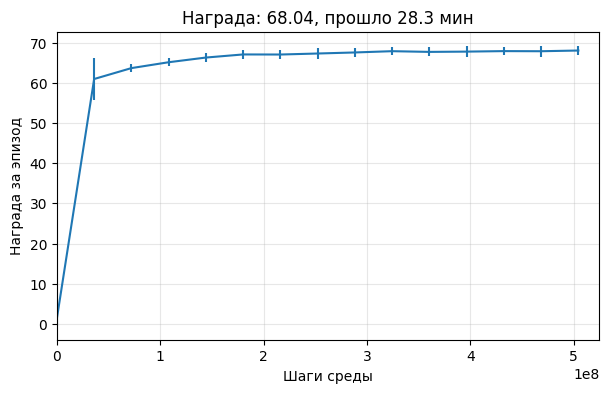

Компиляция: 0:01:05.479707, обучение: 0:27:10.699345
Сохранено: policy.npz, params_final.pkl, go1_policy.py


In [ ]:
#@title Обучение
log_rows, times = [], [datetime.now()]


def progress(num_steps, metrics):
    times.append(datetime.now())
    row = {'step': int(num_steps), 'time_s': (times[-1] - times[0]).total_seconds()}
    row.update({k: float(v) for k, v in metrics.items() if np.ndim(v) == 0})
    log_rows.append(row)
    df = pd.DataFrame(log_rows)
    df.to_csv(f'{OUT_DIR}/metrics.csv', index=False)

    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.errorbar(df['step'], df['eval/episode_reward'], yerr=df.get('eval/episode_reward_std'), color='tab:blue')
    ax.set_xlim(0, NUM_TIMESTEPS * 1.05)
    ax.set_xlabel('Шаги среды')
    ax.set_ylabel('Награда за эпизод')
    ax.set_title(f"Награда: {row['eval/episode_reward']:.2f}, прошло {row['time_s']/60:.1f} мин")
    ax.grid(alpha=0.3)
    fig.savefig(f'{OUT_DIR}/reward_curve.png', dpi=120, bbox_inches='tight')
    display(fig)
    plt.close(fig)


def policy_params_fn(current_step, make_policy, params):
    ck = f'{OUT_DIR}/checkpoints/step_{int(current_step):012d}'
    export_policy_npz(params, ck + '.npz')
    with open(ck + '.pkl', 'wb') as f:
        pickle.dump(jax.device_get(params), f)


ppo_training_params = dict(ppo_params)
network_factory = ppo_networks.make_ppo_networks
if 'network_factory' in ppo_params:
    del ppo_training_params['network_factory']
    network_factory = functools.partial(ppo_networks.make_ppo_networks, **ppo_params.network_factory)

restore = None
if RESUME_FROM:
    with open(RESUME_FROM, 'rb') as f:
        restore = pickle.load(f)
    print('Продолжаю обучение с', RESUME_FROM)

train_fn = functools.partial(
    ppo.train, **ppo_training_params,
    restore_params=restore,
    network_factory=network_factory,
    randomization_fn=registry.get_domain_randomizer('Go1JoystickFlatTerrain'),
    progress_fn=progress,
    policy_params_fn=policy_params_fn,
    seed=SEED,
)

make_inference_fn, params, _ = train_fn(
    environment=env, eval_env=eval_env, wrap_env_fn=wrapper.wrap_for_brax_training)

print(f'Компиляция: {times[1] - times[0]}, обучение: {times[-1] - times[1]}')
export_policy_npz(params, f'{OUT_DIR}/policy.npz')
with open(f'{OUT_DIR}/params_final.pkl', 'wb') as f:
    pickle.dump(jax.device_get(params), f)
shutil.copy('go1_policy.py', f'{OUT_DIR}/go1_policy.py')
print('Сохранено: policy.npz, params_final.pkl, go1_policy.py')

In [ ]:
#@title Проверка: numpy-политика совпадает с JAX-политикой
pol = go1_policy.Go1Policy(f'{OUT_DIR}/policy.npz')
jit_inference = jax.jit(make_inference_fn(params, deterministic=True))
st = jax.jit(eval_env.reset)(jax.random.PRNGKey(1))
step_fn = jax.jit(eval_env.step)
max_err = 0.0
for i in range(50):
    act_jax, _ = jit_inference(st.obs, jax.random.PRNGKey(i))
    act_np = pol.forward(np.asarray(st.obs['state'], dtype=np.float64))
    max_err = max(max_err, float(np.max(np.abs(np.asarray(act_jax) - act_np))))
    st = step_fn(st, act_jax)
print('Максимальное расхождение действий:', max_err)
assert max_err < 1e-3, 'numpy-реализация не совпадает с сетью: проверьте функцию активации/экспорт'
print('OK')

Максимальное расхождение действий: 4.2350516715750075e-07
OK


In [ ]:
#@title Проверка: идёт ли робот вперёд в среде обучения
pol = go1_policy.Go1Policy(f'{OUT_DIR}/policy.npz')
reset_j, step_j = jax.jit(eval_env.reset), jax.jit(eval_env.step)
walk_ok = True
for vx in [v for v in [0.2, 0.4, 0.6] if v <= VX_RANGE[1] + 1e-9]:
    st = reset_j(jax.random.PRNGKey(0))
    st.info['command'] = jp.array([vx, 0.0, 0.0])
    st.info['steps_until_next_cmd'] = jp.array(10**6, dtype=jp.int32)
    w, x, y, z = np.asarray(st.data.qpos[3:7])
    yaw0 = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    p0 = np.asarray(st.data.qpos[:2])
    fell = False
    for i in range(500):  # 10 секунд
        a = pol.forward(np.asarray(st.obs['state'], dtype=np.float64))
        st = step_j(st, jp.asarray(a, dtype=jp.float32))
        if float(st.done) > 0.5:
            fell = True
            break
    d = np.asarray(st.data.qpos[:2]) - p0
    v = (d @ np.array([np.cos(yaw0), np.sin(yaw0)])) / ((i + 1) * eval_env.dt)
    ok = (not fell) and v > 0.6 * vx
    walk_ok &= ok
    print(f'команда {vx:.1f} м/с -> средняя скорость вперёд {v:.2f} м/с' + ('  УПАЛ' if fell else '') + ('' if ok else '  <-- плохо'))
print('Политика ходит в среде обучения' if walk_ok else
      'Политика НЕ ходит как надо даже в среде обучения: дообучите (RESUME_FROM) или поменяйте награды')

команда 0.2 м/с -> средняя скорость вперёд 0.21 м/с
команда 0.4 м/с -> средняя скорость вперёд 0.39 м/с
Политика ходит в среде обучения


In [ ]:
#@title Модель хакатона и функция эпизода
if not os.path.isdir('/content/go1-simulator-public'):
    !git clone -q --depth 1 https://github.com/Urika000/go1-simulator-public /content/go1-simulator-public
SCENE = '/content/go1-simulator-public/models/mujoco/unitree_go1/scene.xml'

hk_model = mujoco.MjModel.from_xml_path(SCENE)
hk_model.actuator_gainprm[:, 0] = 0.0
hk_model.actuator_biasprm[:, :] = 0.0
JOINT_NAMES = [f'{leg}_{k}_joint' for leg in ('FR', 'FL', 'RR', 'RL') for k in ('hip', 'thigh', 'calf')]
QADR = np.array([hk_model.jnt_qposadr[hk_model.joint(n).id] for n in JOINT_NAMES])
DADR = np.array([hk_model.jnt_dofadr[hk_model.joint(n).id] for n in JOINT_NAMES])
TORQUE_LIMIT = np.array([23.7, 23.7, 35.55] * 4)
HOME_KEY = hk_model.keyframe('home').id
TRUNK_ID = hk_model.body('trunk').id
print('timestep:', hk_model.opt.timestep)


def roll_pitch_yaw(q):
    w, x, y, z = q
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    pitch = np.arcsin(np.clip(2 * (w * y - z * x), -1, 1))
    yaw = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    return roll, pitch, yaw


def run_episode(policy, vx, seed=0, warmup=1.5, t_max=90.0, noise=True, stop_on_success=True,
                video=False, fps=30, latency=0.0):
    rng = np.random.default_rng(seed)
    d = mujoco.MjData(hk_model)
    mujoco.mj_resetDataKeyframe(hk_model, d, HOME_KEY)
    if seed > 0:
        d.qvel[0:6] += rng.uniform(-0.1, 0.1, 6)
    mujoco.mj_forward(hk_model, d)
    policy.reset()

    dt = hk_model.opt.timestep
    decim = int(round(policy.ctrl_dt / dt))
    n_steps = int((warmup + t_max) / dt)
    target = policy.default_pose.copy()
    pending = []
    p0 = heading = None
    fall_timer, fell = 0.0, False
    res = dict(vx=vx, seed=seed, latency=latency, success=False, fell=False, distance=0.0, t_3m=np.nan,
               min_height=9.0, max_roll_deg=0.0, max_pitch_deg=0.0, lateral=0.0)
    frames, renderer, cam = [], None, None
    if video:
        renderer = mujoco.Renderer(hk_model, 480, 640)
        cam = mujoco.MjvCamera()
        cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
        cam.trackbodyid = TRUNK_ID
        cam.distance, cam.azimuth, cam.elevation = 1.6, 120, -20

    for i in range(n_steps):
        t = i * dt
        q, dq = d.qpos[QADR].copy(), d.qvel[DADR].copy()
        if i % decim == 0:
            cmd = [0.0, 0.0, 0.0] if t < warmup else [vx, 0.0, 0.0]
            quat, gyro = d.qpos[3:7].copy(), d.qvel[3:6].copy()
            qo, dqo = q, dq
            if noise:
                gyro = gyro + rng.uniform(-0.1, 0.1, 3)
                qo = q + rng.uniform(-0.01, 0.01, 12)
                dqo = dq + rng.uniform(-0.5, 0.5, 12)
            pending.append((t + latency, policy.step(quat, gyro, qo, dqo, cmd)))
        while pending and pending[0][0] <= t + 1e-9:
            target = pending.pop(0)[1]
        tau = np.clip(policy.kp * (target - q) + policy.kd * (0.0 - dq), -TORQUE_LIMIT, TORQUE_LIMIT)
        d.qfrc_applied[:] = 0.0
        d.qfrc_applied[DADR] = tau
        mujoco.mj_step(hk_model, d)

        roll, pitch, yaw = roll_pitch_yaw(d.qpos[3:7])
        h = d.qpos[2]
        if p0 is None and t + dt >= warmup:
            p0, heading = d.qpos[0:2].copy(), yaw
        if p0 is not None:
            delta = d.qpos[0:2] - p0
            fwd = np.array([np.cos(heading), np.sin(heading)])
            res['distance'] = float(delta @ fwd)
            res['lateral'] = float(delta @ np.array([-fwd[1], fwd[0]]))
            res['min_height'] = min(res['min_height'], float(h))
            res['max_roll_deg'] = max(res['max_roll_deg'], abs(np.degrees(roll)))
            res['max_pitch_deg'] = max(res['max_pitch_deg'], abs(np.degrees(pitch)))
            bad = h < 0.16 or abs(np.degrees(roll)) > 50 or abs(np.degrees(pitch)) > 50
            fall_timer = fall_timer + dt if bad else 0.0
            if fall_timer > 0.5:
                res['fell'] = True
                break
            if not res['success'] and res['distance'] >= 3.0:
                res['success'] = True
                res['t_3m'] = t - warmup
                if stop_on_success and not video:
                    break
        if video and i % int(round(1 / (fps * dt))) == 0:
            renderer.update_scene(d, cam)
            frames.append(renderer.render())
        if video and res['success'] and t - warmup > res['t_3m'] + 2.0:
            break
    res['success'] = res['success'] and not res['fell']
    return (res, frames) if video else res

timestep: 0.002


In [ ]:
#@title Прогон: 5 скоростей x 10 эпизодов, без задержки и с задержкой 20 мс
importlib.reload(go1_policy)
policy = go1_policy.Go1Policy(f'{OUT_DIR}/policy.npz')
rows = []
for latency in [0.0, 0.02]:
    for vx in [v for v in [0.2, 0.3, 0.4, 0.5, 0.6] if v <= VX_RANGE[1] + 1e-9]:
        for seed in range(10):
            rows.append(run_episode(policy, vx, seed=seed, latency=latency))
        print(f'задержка {latency*1000:.0f} мс, vx={vx}: успехов {sum(r["success"] for r in rows[-10:])}/10')
res_df = pd.DataFrame(rows)
res_df.to_csv(f'{OUT_DIR}/sim2sim_results.csv', index=False)

summary = res_df.groupby(['latency', 'vx']).agg(
    успехов=('success', 'sum'), падений=('fell', 'sum'), путь_м=('distance', 'mean'),
    время_3м_с=('t_3m', 'mean'), мин_высота=('min_height', 'min'),
    макс_крен=('max_roll_deg', 'max'), макс_тангаж=('max_pitch_deg', 'max'), снос_м=('lateral', 'mean'))
display(summary.round(3))

# Скорость выбираем по худшему случаю (с задержкой).
worst = summary.xs(0.02, level='latency')['успехов']
best = worst.max()
cands = worst.index[worst == best].tolist()
preferred = float(min(cands, key=lambda v: abs(v - 0.35)))
print(f'Рекомендуемая preferred_speed_mps = {preferred} (успехов с задержкой 20 мс: {int(best)}/10)')
with open(f'{OUT_DIR}/sim2sim_summary.json', 'w') as f:
    json.dump({'preferred_speed_mps': preferred,
               'success_by_speed_latency_0ms': {str(k): int(v) for k, v in summary.xs(0.0, level='latency')['успехов'].items()},
               'success_by_speed_latency_20ms': {str(k): int(v) for k, v in worst.items()}}, f, indent=2)

задержка 0 мс, vx=0.2: успехов 10/10
задержка 0 мс, vx=0.3: успехов 10/10
задержка 0 мс, vx=0.4: успехов 10/10
задержка 0 мс, vx=0.5: успехов 10/10
задержка 20 мс, vx=0.2: успехов 10/10
задержка 20 мс, vx=0.3: успехов 10/10
задержка 20 мс, vx=0.4: успехов 10/10
задержка 20 мс, vx=0.5: успехов 10/10


успехов  падений  путь_м  время_3м_с  мин_высота  макс_крен  \
latency vx                                                                 
0.00    0.2       10        0     3.0      14.858       0.271      1.958   
        0.3       10        0     3.0      10.375       0.271      2.157   
        0.4       10        0     3.0       8.054       0.271      2.153   
        0.5       10        0     3.0       6.706       0.271      2.503   
0.02    0.2       10        0     3.0      17.160       0.271      3.519   
        0.3       10        0     3.0      12.116       0.271      3.071   
        0.4       10        0     3.0       9.262       0.271      2.520   
        0.5       10        0     3.0       7.489       0.271      3.429   

             макс_тангаж  снос_м  
latency vx                        
0.00    0.2        3.999   0.177  
        0.3        3.331   0.176  
        0.4        2.997   0.245  
        0.5        3.088   0.262  
0.02    0.2        4.411   0.457  
        0.3        4.102   0.488  
        0.4        3.818   0.353  
        0.5        3.739   0.403

Рекомендуемая preferred_speed_mps = 0.3 (успехов с задержкой 20 мс: 10/10)


In [ ]:
#@title Видео ходьбы в модели хакатона
res, frames = run_episode(policy, preferred, seed=0, t_max=15.0, noise=False, video=True, latency=0.02)
print(res)
media.write_video(f'{OUT_DIR}/sim2sim_walk.mp4', frames, fps=30)
media.show_video(frames, fps=30)

{'vx': 0.3, 'seed': 0, 'latency': 0.02, 'success': True, 'fell': False, 'distance': 3.4727856930465095, 't_3m': 12.186, 'min_height': 0.27127376918829615, 'max_roll_deg': np.float64(2.434532172166916), 'max_pitch_deg': np.float64(3.7916589957287794), 'lateral': 0.6327981558626206}


This browser does not support the video tag.


In [ ]:
#@title Список сохранённых файлов
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f'{os.path.relpath(p, OUT_DIR):55s} {os.path.getsize(p)/1024:8.1f} КБ')

config.json                                                  4.5 КБ
go1_policy.py                                                5.1 КБ
metrics.csv                                                 16.3 КБ
params_final.pkl                                          1643.1 КБ
policy.npz                                                 755.3 КБ
reward_curve.png                                            27.9 КБ
sim2sim_results.csv                                          9.9 КБ
sim2sim_summary.json                                         0.2 КБ
sim2sim_walk.mp4                                          2186.2 КБ
checkpoints/step_000000000000.npz                          755.3 КБ
checkpoints/step_000000000000.pkl                         1643.1 КБ
checkpoints/step_000036044800.npz                          755.3 КБ
checkpoints/step_000036044800.pkl                         1643.1 КБ
checkpoints/step_000072089600.npz                          755.3 КБ
checkpoints/step_000072089600.pkl               